In [1]:
# Environment check: run inside the submitted environment, do not install packages every run.
import sys
import pyspark

print(f"Python: {sys.version.split()[0]}")
print(f"PySpark: {pyspark.__version__}")


Python: 3.12.13
PySpark: 4.0.2


In [2]:
# Data path setup: works in both Google Colab and a local project folder.
from pathlib import Path

try:
    from google.colab import drive
    drive.mount('/content/drive/')
    data_path = "/content/drive/MyDrive/Colab Notebooks/CDS527/"
    csv_path = data_path + "amazon_reviews.csv"
except ModuleNotFoundError:
    project_dir = Path.cwd()
    data_path = str(project_dir) + "/"
    csv_path = str(project_dir / "amazon_reviews.csv")

print(f"Using data file: {csv_path}")


Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).
Using data file: /content/drive/MyDrive/Colab Notebooks/CDS527/amazon_reviews.csv


Base Model and Data Preprocessing

In [3]:
# create entry points to spark
from pyspark.sql import SparkSession

ss = (
    SparkSession.builder
    .master("local[2]")
    .appName("CDS527-AmazonReviews")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.python.worker.reuse", "true")
    .getOrCreate()
)
ss.sparkContext.setLogLevel("WARN")


In [4]:
# Load Amazon Reviews dataset (PySpark native CSV read)

df = ss.read.csv(
    path=csv_path,
    header=True,
    inferSchema=True,
    ignoreLeadingWhiteSpace=True,
    ignoreTrailingWhiteSpace=True,
    quote='"',
    escape='"',
    multiLine=True,
)

df.show(5, truncate=60)
df.printSchema()


+------------------------------------------------------------+--------------+
|                                                  reviewText|classification|
+------------------------------------------------------------+--------------+
|I bought this on black friday last year and took a chance...|             1|
|I bought it for my new galaxy note and I realized the dev...|             1|
|Received one - didn't work. Not readable on my Mac or my ...|             1|
|after doing some tests between a generic memory card and ...|             1|
|Just started unmounting and remounting all by itself.  Re...|             1|
+------------------------------------------------------------+--------------+
only showing top 5 rows
root
 |-- reviewText: string (nullable = true)
 |-- classification: integer (nullable = true)



In [5]:
# Global experiment setup (keep this consistent across all tasks)
SEED = 2026
SPLIT_WEIGHTS = [0.8, 0.2]
MAIN_METRIC = "f1"

print(f"SEED = {SEED}, SPLIT_WEIGHTS = {SPLIT_WEIGHTS}, MAIN_METRIC = {MAIN_METRIC}")


SEED = 2026, SPLIT_WEIGHTS = [0.8, 0.2], MAIN_METRIC = f1


In [6]:
# Data Cleaning (PySpark Native)
from pyspark.sql.functions import col, lower, regexp_replace, trim, when

# Drop rows with null values in critical columns and normalize column types.
df = (
    df.dropna(subset=["reviewText", "classification"])
    .dropDuplicates()
    .withColumn("classification", col("classification").cast("int"))
    .dropna(subset=["classification"])
)

# Clean text with Spark SQL expressions.
df = df.withColumn("reviewText", lower(col("reviewText")))
df = df.withColumn("reviewText", regexp_replace(col("reviewText"), r"[^a-zA-Z0-9\s]", ""))
df = df.withColumn("reviewText", trim(regexp_replace(col("reviewText"), r"\s+", " ")))

# Create 3-class sentiment labels based on the dataset description:
# 0 = Negative (1-2 stars), 1 = Neutral (3 stars), 2 = Positive (4-5 stars).
df = df.withColumn(
    "label",
    when(col("classification") <= 2, 0)
    .when(col("classification") == 3, 1)
    .when(col("classification") >= 4, 2)
)

df = df.dropna(subset=["label"])

# Show label distribution.
df.groupBy("label").count().orderBy("label").show()


+-----+-----+
|label|count|
+-----+-----+
|    0|   65|
|    1|   28|
|    2|  889|
+-----+-----+



In [7]:
# Feature Extraction: TF-IDF

from pyspark.ml.feature import RegexTokenizer, StopWordsRemover, CountVectorizer, IDF

# Tokenize sentence into words
tokenizer = RegexTokenizer(inputCol="reviewText", outputCol="words", pattern=r"\W")

# Remove stop words
stop_remover = StopWordsRemover(inputCol="words", outputCol="filtered_words")

# Generate term frequency vector
cv = CountVectorizer(inputCol="filtered_words", outputCol="raw_features", vocabSize=5000)

# Compute TF-IDF features
idf = IDF(inputCol="raw_features", outputCol="features")

In [8]:
# Baseline Model: Logistic Regression

from pyspark.ml.classification import LogisticRegression

lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=10,
    regParam=0.01,
    elasticNetParam=0.0
)

In [9]:
# Create ML Pipeline

from pyspark.ml import Pipeline

pipeline = Pipeline(stages=[tokenizer, stop_remover, cv, idf, lr])

In [10]:
# Split Train / Test Data (deterministic and reusable across all tasks)
from pyspark.sql import functions as F

df_split = df.withColumn(
    "split_bucket",
    F.pmod(F.abs(F.xxhash64("reviewText", "label")), F.lit(10))
)
train_df = df_split.filter(F.col("split_bucket") < 8).drop("split_bucket")
test_df = df_split.filter(F.col("split_bucket") >= 8).drop("split_bucket")

print(f"Train size: {train_df.count()}, Test size: {test_df.count()}")


Train size: 790, Test size: 192


In [11]:
# Train Model
model = pipeline.fit(train_df)

In [12]:
# Predict on Test Data
predictions = model.transform(test_df)

In [13]:
# Model Evaluation (FOR 3-CLASS CLASSIFICATION)
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Primary evaluator: weighted F1 (used consistently across the project)
f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)
baseline_f1 = f1_evaluator.evaluate(predictions)

# Optional secondary metric (reported only for reference)
acc_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)
baseline_accuracy = acc_evaluator.evaluate(predictions)

print("BASELINE MODEL RESULTS (3-CLASS)")
print(f"Primary metric (F1) = {baseline_f1:.4f}")
print(f"Reference metric (Accuracy) = {baseline_accuracy:.4f}")


BASELINE MODEL RESULTS (3-CLASS)
Primary metric (F1) = 0.9020
Reference metric (Accuracy) = 0.9062


In [14]:
# Show prediction samples
predictions.select("reviewText", "label", "prediction", "probability").show(10, truncate=60)

+------------------------------------------------------------+-----+----------+------------------------------------------------------------+
|                                                  reviewText|label|prediction|                                                 probability|
+------------------------------------------------------------+-----+----------+------------------------------------------------------------+
|this review is for the sandisk ultra 32 gb microsdhc clas...|    0|       2.0|  [0.06506131947506646,0.037790177456769,0.8971485030681644]|
|used for two months in samsung galaxy fizzled then failed...|    0|       2.0|   [0.4622816141404553,0.0616488640700818,0.476069521789463]|
|everything transfered over to my new sd card fine but now...|    0|       0.0|  [0.5306372835020476,0.04964505014426337,0.419717666353689]|
|tried this with its adapter on dslr camera and got some e...|    0|       2.0|[0.02646308150692562,0.02157784636818184,0.9519590721248925]|
|title pretty

Model Comparison and Word Embedding Integration

**Step1**: Integrates multiple data analysis models

Main Spark feature comparison setup.

The primary implementation remains based on PySpark/Spark ML. TF-IDF and Spark Word2Vec are fitted inside Spark pipelines on the training split only. A separate GloVe experiment is added as a supplementary pretrained embedding comparison using Spark NLP pretrained embeddings.


In [15]:
from pyspark.ml.feature import Tokenizer, RegexTokenizer, StopWordsRemover, CountVectorizer, IDF, Word2Vec
from pyspark.ml.classification import DecisionTreeClassifier, RandomForestClassifier, LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml import Pipeline
from pyspark.sql import functions as F


In [16]:
# Quick dataset info (Spark-only)
print(f"Total rows in cleaned dataset: {df.count()}")
df.groupBy("label").count().orderBy("label").show()


Total rows in cleaned dataset: 982
+-----+-----+
|label|count|
+-----+-----+
|    0|   65|
|    1|   28|
|    2|  889|
+-----+-----+



In [17]:
def build_feature_stages(feature_name):
    """Return Spark ML feature stages fitted only inside the training pipeline."""
    tokenizer_cmp = RegexTokenizer(inputCol="reviewText", outputCol="cmp_words", pattern=r"\W")
    stop_remover_cmp = StopWordsRemover(inputCol="cmp_words", outputCol="cmp_filtered_words")

    if feature_name == "tfidf":
        cv_cmp = CountVectorizer(inputCol="cmp_filtered_words", outputCol="cmp_raw_features", vocabSize=5000, minDF=2)
        idf_cmp = IDF(inputCol="cmp_raw_features", outputCol="features")
        return [tokenizer_cmp, stop_remover_cmp, cv_cmp, idf_cmp]

    if feature_name == "word2vec":
        w2v_cmp = Word2Vec(
            inputCol="cmp_filtered_words",
            outputCol="features",
            vectorSize=100,
            minCount=2,
            seed=SEED,
        )
        return [tokenizer_cmp, stop_remover_cmp, w2v_cmp]

    raise ValueError(f"Unknown feature_name: {feature_name}")


In [18]:
evaluator_f1 = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1",
)

def make_classifier(model_name):
    if model_name == "DecisionTree":
        return DecisionTreeClassifier(featuresCol="features", labelCol="label", predictionCol="prediction", seed=SEED)
    if model_name == "RandomForest":
        return RandomForestClassifier(featuresCol="features", labelCol="label", predictionCol="prediction", numTrees=30, seed=SEED)
    if model_name == "LogisticRegression":
        return LogisticRegression(
            featuresCol="features",
            labelCol="label",
            predictionCol="prediction",
            family="multinomial",
            maxIter=80,
        )
    raise ValueError(f"Unknown model_name: {model_name}")

def evaluate_predictions(pred):
    acc_evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName="accuracy",
    )
    return {
        "Accuracy": acc_evaluator.evaluate(pred),
        "F1": evaluator_f1.evaluate(pred),
    }


In [19]:
feature_names = ["tfidf", "word2vec"]
model_names = ["DecisionTree", "RandomForest", "LogisticRegression"]


In [20]:
comparison_records = []

for feature_name in feature_names:
    for model_name in model_names:
        pipeline_cmp = Pipeline(stages=build_feature_stages(feature_name) + [make_classifier(model_name)])
        fitted_cmp = pipeline_cmp.fit(train_df)
        pred_cmp = fitted_cmp.transform(test_df)
        scores = evaluate_predictions(pred_cmp)
        comparison_records.append(
            {
                "Model": model_name,
                "Embedding": feature_name,
                "Accuracy": scores["Accuracy"],
                "F1": scores["F1"],
            }
        )


In [21]:
import pandas as pd

# The comparison table has only a few rows; keep it on the driver for display/plotting.
# Model training and feature extraction above remain Spark ML pipelines.
comparison_pd = pd.DataFrame(comparison_records).sort_values("F1", ascending=False).reset_index(drop=True)


In [22]:
print("Model comparison before CV tuning; all feature estimators are fitted inside train-only Spark pipelines:")
print(comparison_pd.to_string(index=False))


Model comparison before CV tuning; all feature estimators are fitted inside train-only Spark pipelines:
             Model Embedding  Accuracy       F1
      DecisionTree     tfidf  0.932292 0.915548
      RandomForest     tfidf  0.927083 0.892005
      RandomForest  word2vec  0.927083 0.892005
LogisticRegression  word2vec  0.885417 0.882173
      DecisionTree  word2vec  0.906250 0.881489
LogisticRegression     tfidf  0.854167 0.875971


Supplementary GloVe Pretrained Embedding Comparison (Spark NLP)

This section adds a pretrained GloVe comparison by directly calling a Spark NLP pretrained embedding model. The common cleaned dataset and split remain unchanged, while token-level embeddings are generated through Spark NLP and then aggregated to review-level vectors for downstream classifier comparison. The primary submitted workflow remains PySpark/Spark ML, with this block serving as the supplementary pretrained embedding experiment.


In [23]:
# Supplementary GloVe comparison: Spark NLP pretrained embeddings + lightweight driver-side classifiers.
# Main pipeline remains PySpark/Spark ML; this block is only for the extra pretrained embedding comparison.
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score
from sklearn.tree import DecisionTreeClassifier as SkDecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier as SkRandomForestClassifier
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

try:
    import sparknlp
    from sparknlp.base import DocumentAssembler, Finisher
    from sparknlp.annotator import Tokenizer as NlpTokenizer, Normalizer, StopWordsCleaner, WordEmbeddingsModel
    from pyspark.ml import Pipeline as SparkMlPipeline

    # Start/attach Spark NLP session if needed.
    spark = sparknlp.start()

    glove_input_train = train_df.select("label", "reviewText")
    glove_input_test = test_df.select("label", "reviewText")

    document = DocumentAssembler().setInputCol("reviewText").setOutputCol("document")
    tokenizer = NlpTokenizer().setInputCols(["document"]).setOutputCol("token")
    normalizer = Normalizer().setInputCols(["token"]).setOutputCol("normalized")
    stopwords = StopWordsCleaner.pretrained("stopwords_iso", "en") \
        .setInputCols(["normalized"]) \
        .setOutputCol("clean_tokens")

    # Directly call Spark NLP pretrained GloVe embeddings.
    embeddings = WordEmbeddingsModel.pretrained("glove_100d", "en") \
        .setInputCols(["document", "clean_tokens"]) \
        .setOutputCol("embeddings")

    finisher = Finisher() \
        .setInputCols(["embeddings"]) \
        .setOutputCols(["embedding_vectors"]) \
        .setOutputAsArray(True) \
        .setCleanAnnotations(False)

    glove_pipeline = SparkMlPipeline(stages=[document, tokenizer, normalizer, stopwords, embeddings, finisher])
    glove_model = glove_pipeline.fit(glove_input_train)

    train_emb_df = glove_model.transform(glove_input_train).select("label", "embeddings")
    test_emb_df = glove_model.transform(glove_input_test).select("label", "embeddings")

    glove_dim = 100

    def average_embedding(annotation_list):
        if not annotation_list:
            return np.zeros(glove_dim, dtype=float)
        vectors = [np.array(ann.embeddings, dtype=float) for ann in annotation_list if ann.embeddings]
        if not vectors:
            return np.zeros(glove_dim, dtype=float)
        return np.mean(vectors, axis=0)

    train_rows = train_emb_df.collect()
    test_rows = test_emb_df.collect()

    X_train_glove = np.vstack([average_embedding(row["embeddings"]) for row in train_rows])
    y_train_glove = np.array([int(row["label"]) for row in train_rows])
    X_test_glove = np.vstack([average_embedding(row["embeddings"]) for row in test_rows])
    y_test_glove = np.array([int(row["label"]) for row in test_rows])

    glove_classifiers = [
        ("DecisionTree", SkDecisionTreeClassifier(random_state=SEED, max_depth=5)),
        ("RandomForest", SkRandomForestClassifier(n_estimators=50, random_state=SEED, max_depth=8)),
        ("LogisticRegression", SkLogisticRegression(max_iter=1000, random_state=SEED, class_weight="balanced")),
    ]

    glove_records = []
    for model_name, clf in glove_classifiers:
        clf.fit(X_train_glove, y_train_glove)
        y_pred_glove = clf.predict(X_test_glove)
        glove_records.append({
            "Model": model_name,
            "Embedding": "glove_sparknlp",
            "Accuracy": accuracy_score(y_test_glove, y_pred_glove),
            "F1": f1_score(y_test_glove, y_pred_glove, average="weighted"),
        })

    glove_supplementary_pd = pd.DataFrame(glove_records).sort_values("F1", ascending=False).reset_index(drop=True)
    comparison_all_pd = pd.concat([comparison_pd, glove_supplementary_pd], ignore_index=True).sort_values("F1", ascending=False).reset_index(drop=True)

    print("Supplementary GloVe comparison results (Spark NLP pretrained glove_100d):")
    print(glove_supplementary_pd.to_string(index=False))
    print("\nCombined pre-tuning comparison including TF-IDF, Spark Word2Vec, and supplementary Spark NLP GloVe:")
    print(comparison_all_pd.to_string(index=False))

except Exception as exc:
    glove_supplementary_pd = pd.DataFrame(columns=["Model", "Embedding", "Accuracy", "F1"])
    comparison_all_pd = comparison_pd.copy()
    print("Supplementary Spark NLP GloVe comparison skipped because pretrained resources were unavailable.")
    print(f"Reason: {exc}")


Supplementary Spark NLP GloVe comparison skipped because pretrained resources were unavailable.
Reason: No module named 'sparknlp'


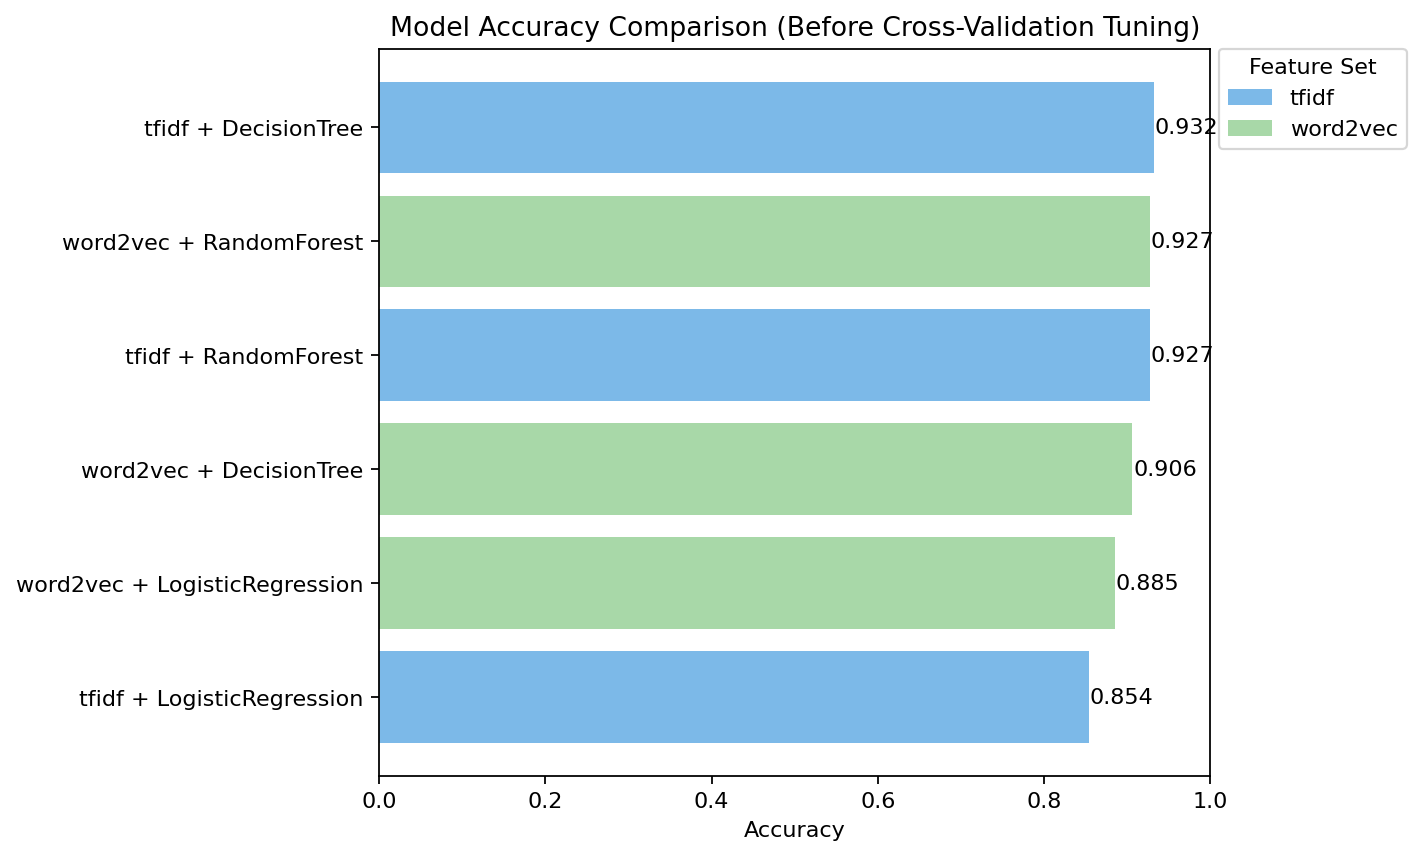

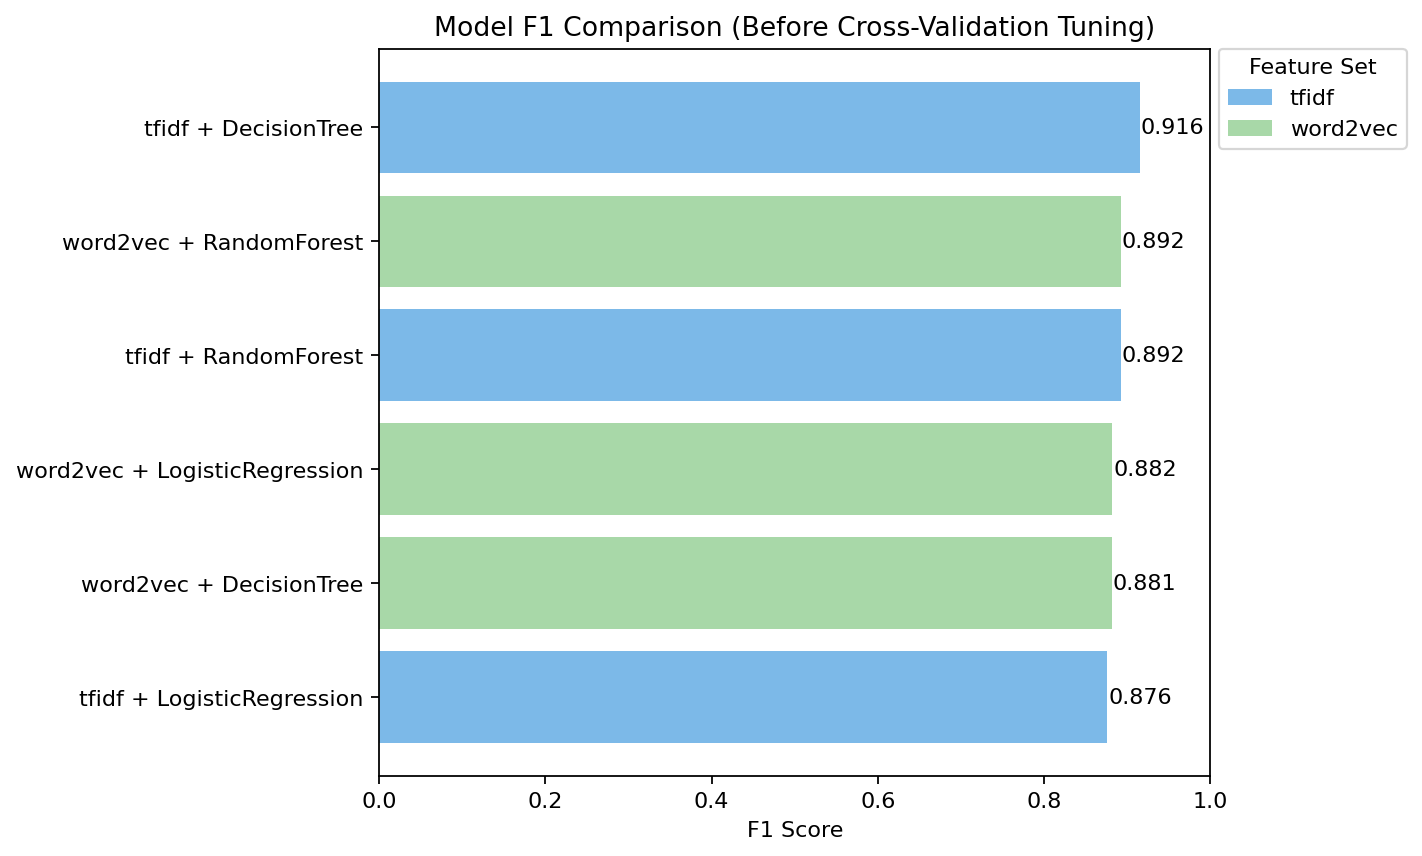

In [24]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from IPython.display import display, Image
from io import BytesIO


def display_figure(fig=None):
    """Persist matplotlib figures as PNG outputs, including non-interactive backends."""
    if fig is None:
        fig = plt.gcf()
    buffer = BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight", dpi=160)
    buffer.seek(0)
    display(Image(data=buffer.getvalue()))
    plt.close(fig)


plot_comparison_pd = comparison_all_pd.copy() if "comparison_all_pd" in globals() else comparison_pd.copy()
emb_colors = {'tfidf': '#7CB9E8', 'word2vec': '#A8D8A8', 'glove': '#F4A261'}
legend_elements = [Patch(facecolor=v, label=k) for k, v in emb_colors.items() if k in set(plot_comparison_pd["Embedding"])]

# Accuracy
plot_comparison_pd["combo"] = plot_comparison_pd["Embedding"] + " + " + plot_comparison_pd["Model"]
comp_acc = plot_comparison_pd.sort_values("Accuracy", ascending=True).reset_index(drop=True)
y = np.arange(len(comp_acc))

fig = plt.figure(figsize=(9, 5.5))
plt.barh(y, comp_acc["Accuracy"], color=[emb_colors[e] for e in comp_acc["Embedding"]])
for i, acc in enumerate(comp_acc["Accuracy"]):
    plt.text(acc + 0.001, i, f"{acc:.3f}", va='center')
plt.xlim(0, min(1.0, comp_acc["Accuracy"].max() + 0.15))
plt.yticks(y, comp_acc["combo"])
plt.xlabel("Accuracy")
plt.title("Model Accuracy Comparison (Before Cross-Validation Tuning)")
plt.legend(handles=legend_elements, title="Feature Set",
           loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
plt.tight_layout()
display_figure(fig)

# F1
comp_f1 = plot_comparison_pd.sort_values("F1", ascending=True).reset_index(drop=True)
y = np.arange(len(comp_f1))

fig = plt.figure(figsize=(9, 5.5))
plt.barh(y, comp_f1["F1"], color=[emb_colors[e] for e in comp_f1["Embedding"]])
for i, f1_value in enumerate(comp_f1["F1"]):
    plt.text(f1_value + 0.001, i, f"{f1_value:.3f}", va='center')
plt.xlim(0, min(1.0, comp_f1["F1"].max() + 0.15))
plt.yticks(y, comp_f1["combo"])
plt.xlabel("F1 Score")
plt.title("Model F1 Comparison (Before Cross-Validation Tuning)")
plt.legend(handles=legend_elements, title="Feature Set",
           loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
plt.tight_layout()
display_figure(fig)


Improved Hyperparameter Tuning (Cross-Validation)

This section performs Spark `CrossValidator` tuning for Decision Tree, Random Forest, and Logistic Regression with both TF-IDF and Spark Word2Vec feature pipelines. All feature estimators are fitted only on the training folds to avoid test-set leakage.


In [25]:
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.ml.classification import DecisionTreeClassifier, RandomForestClassifier, LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# Unified evaluator for tuning/model selection
evaluator_f1 = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1",
)

def make_tuning_grid(model, model_name):
    builder = ParamGridBuilder()
    if model_name == "DecisionTree":
        return (
            builder
            .addGrid(model.maxDepth, [3, 5])
            .addGrid(model.minInstancesPerNode, [1, 2])
            .build()
        )
    if model_name == "RandomForest":
        return (
            builder
            .addGrid(model.numTrees, [20])
            .addGrid(model.maxDepth, [5, 8])
            .build()
        )
    if model_name == "LogisticRegression":
        return (
            builder
            .addGrid(model.regParam, [0.01, 0.1])
            .addGrid(model.elasticNetParam, [0.0, 0.5])
            .build()
        )
    raise ValueError(f"Unknown model_name: {model_name}")

def cv_tune_and_eval(feature_name, model_name):
    model = make_classifier(model_name)
    pipeline_tune = Pipeline(stages=build_feature_stages(feature_name) + [model])
    param_grid = make_tuning_grid(model, model_name)

    cv = CrossValidator(
        estimator=pipeline_tune,
        estimatorParamMaps=param_grid,
        evaluator=evaluator_f1,
        numFolds=2,
        seed=SEED,
        parallelism=1,
    )
    cv_model = cv.fit(train_df)
    pred = cv_model.transform(test_df)
    scores = evaluate_predictions(pred)

    return {
        "Model": model_name,
        "Embedding": feature_name,
        "Accuracy": scores["Accuracy"],
        "F1": scores["F1"],
    }


In [26]:
tuning_model_names = ["DecisionTree", "RandomForest", "LogisticRegression"]


In [27]:
def run_tuning_batch(feature_name):
    batch_results = []
    for model_name in tuning_model_names:
        print(f"[{feature_name}] Running {model_name}...")
        batch_results.append(cv_tune_and_eval(feature_name, model_name))
        ss.catalog.clearCache()
    return batch_results


In [28]:
# Batch 1: run CV tuning with TF-IDF features.
results_tfidf = run_tuning_batch("tfidf")
result_pd_tfidf = pd.DataFrame(results_tfidf).sort_values("F1", ascending=False)
print("Batch 1 complete: TF-IDF CV tuning results")
print(result_pd_tfidf.to_string(index=False))


[tfidf] Running DecisionTree...
[tfidf] Running RandomForest...
[tfidf] Running LogisticRegression...
Batch 1 complete: TF-IDF CV tuning results
             Model Embedding  Accuracy       F1
      DecisionTree     tfidf  0.942708 0.923850
LogisticRegression     tfidf  0.932292 0.916741
      RandomForest     tfidf  0.921875 0.889397


In [29]:
# Batch 2: run CV tuning with Spark Word2Vec features.
results_word2vec = run_tuning_batch("word2vec")
result_pd_word2vec = pd.DataFrame(results_word2vec).sort_values("F1", ascending=False)
print("Batch 2 complete: Word2Vec CV tuning results")
print(result_pd_word2vec.to_string(index=False))


[word2vec] Running DecisionTree...
[word2vec] Running RandomForest...
[word2vec] Running LogisticRegression...
Batch 2 complete: Word2Vec CV tuning results
             Model Embedding  Accuracy       F1
      RandomForest  word2vec  0.927083 0.892005
LogisticRegression  word2vec  0.927083 0.892005
      DecisionTree  word2vec  0.916667 0.886775


In [30]:
# Merge both batches for final comparison table/plots.
result_pd = pd.concat([result_pd_tfidf, result_pd_word2vec], ignore_index=True).sort_values("F1", ascending=False)
print("CV tuning results (ranked by primary metric F1):")
print(result_pd.to_string(index=False))


CV tuning results (ranked by primary metric F1):
             Model Embedding  Accuracy       F1
      DecisionTree     tfidf  0.942708 0.923850
LogisticRegression     tfidf  0.932292 0.916741
      RandomForest  word2vec  0.927083 0.892005
LogisticRegression  word2vec  0.927083 0.892005
      RandomForest     tfidf  0.921875 0.889397
      DecisionTree  word2vec  0.916667 0.886775


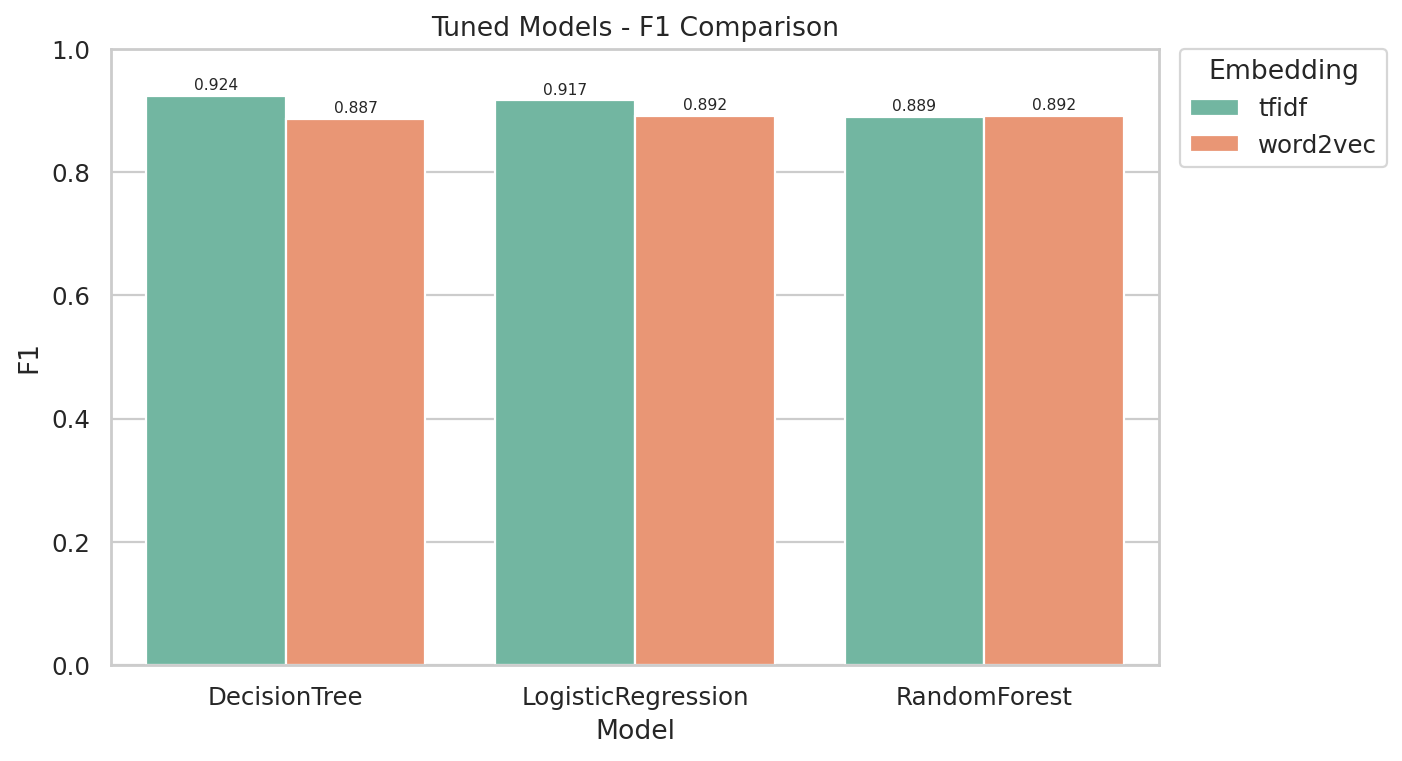

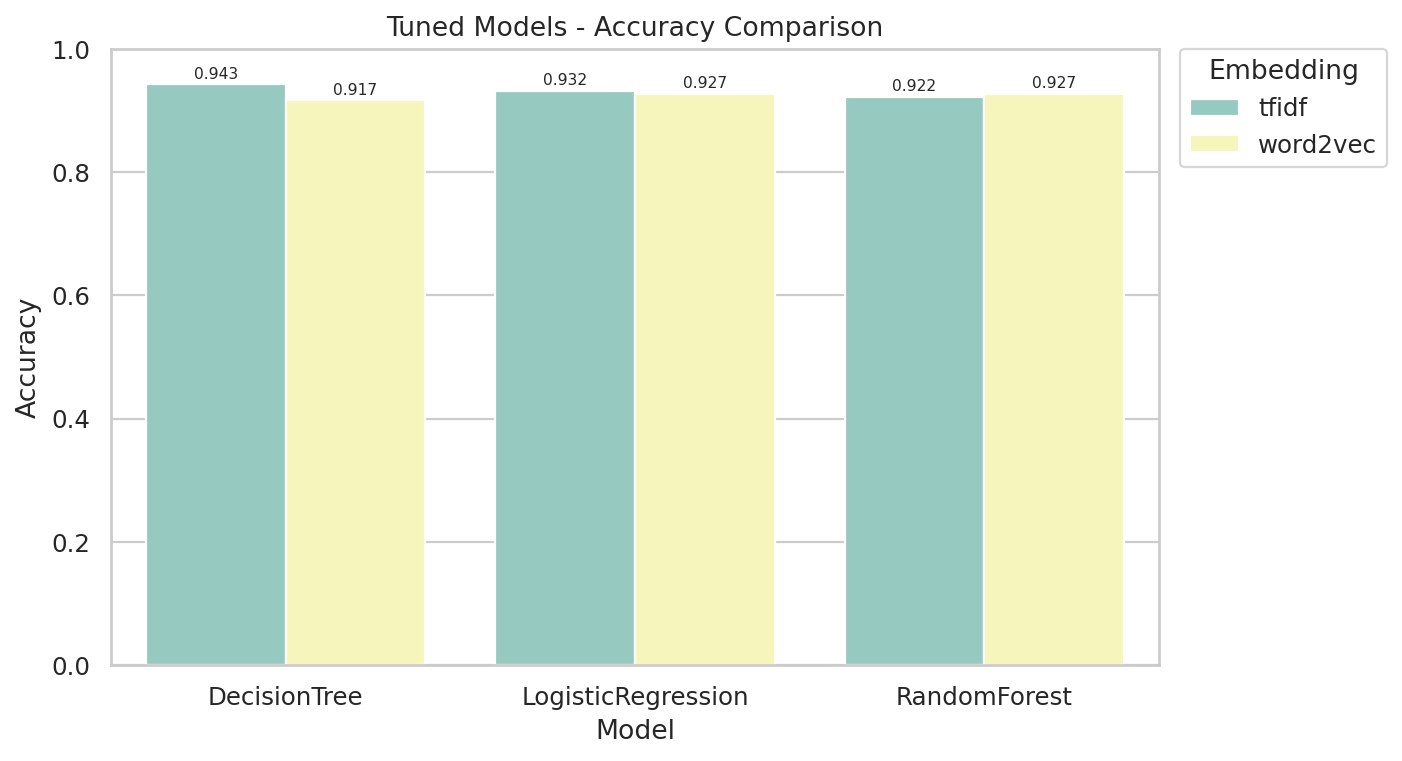

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")


def add_bar_labels(ax, decimal=3):
    for bar in ax.patches:
        height = bar.get_height()
        if height > 0:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                height + 0.005,
                f"{height:.{decimal}f}",
                ha='center', va='bottom', fontsize=7
            )

fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
sns.barplot(data=result_pd, x="Model", y="F1", hue="Embedding", palette="Set2", ax=ax)
add_bar_labels(ax)
ax.set_title("Tuned Models - F1 Comparison")
ax.set_ylim(0, 1.0)
ax.legend(title="Embedding", loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
fig.subplots_adjust(right=0.78)
display_figure(fig)

fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
sns.barplot(data=result_pd, x="Model", y="Accuracy", hue="Embedding", palette="Set3", ax=ax)
add_bar_labels(ax)
ax.set_title("Tuned Models - Accuracy Comparison")
ax.set_ylim(0, 1.0)
ax.legend(title="Embedding", loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
fig.subplots_adjust(right=0.78)
display_figure(fig)


Model Improvement & Innovation

On top of the baseline TF-IDF + Logistic Regression pipeline, we test three improvement strategies and compare their actual F1 against the baseline instead of assuming improvement:

- **Class-imbalance aware training**: compute inverse-frequency class weights on the training set and train LR with `weightCol`.
- **Richer text features**: add **bi-grams** (n=2) and combine them with unigram TF-IDF features.
- **Systematic tuning**: use Spark `CrossValidator` to tune `regParam` and `elasticNetParam` for multinomial LR.

We keep the same label definition, split rule, and weighted F1 metric so results are directly comparable.


In [32]:
# Improved Spark ML pipeline for 3-class sentiment
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    RegexTokenizer,
    StopWordsRemover,
    NGram,
    CountVectorizer,
    IDF,
    VectorAssembler,
)
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

# Rebuild clean split for the improvement experiment with the same deterministic rule.
df_split_t3 = df.withColumn(
    "split_bucket",
    F.pmod(F.abs(F.xxhash64("reviewText", "label")), F.lit(10))
)
train_df_t3 = df_split_t3.filter(F.col("split_bucket") < 8).drop("split_bucket")
test_df_t3 = df_split_t3.filter(F.col("split_bucket") >= 8).drop("split_bucket")

# Class weights from the training set only. The collect is limited to three aggregate rows.
label_counts = train_df_t3.groupBy("label").count().collect()
counts = {r["label"]: r["count"] for r in label_counts}

total = float(sum(counts.values()))
num_classes = float(len(counts))
weights = {lbl: total / (num_classes * float(cnt)) for lbl, cnt in counts.items()}

weight_expr = None
for lbl in sorted(weights.keys()):
    cond = F.col("label") == F.lit(lbl)
    if weight_expr is None:
        weight_expr = F.when(cond, F.lit(float(weights[lbl])))
    else:
        weight_expr = weight_expr.when(cond, F.lit(float(weights[lbl])))
weight_expr = weight_expr.otherwise(F.lit(1.0))

train_df_w = train_df_t3.withColumn("classWeight", weight_expr)
test_df_w = test_df_t3.withColumn("classWeight", weight_expr)

# Feature pipeline: unigram + bigram TF-IDF.
tokenizer = RegexTokenizer(inputCol="reviewText", outputCol="words", pattern=r"\W")
stopper = StopWordsRemover(inputCol="words", outputCol="filtered_words")
ngram2 = NGram(n=2, inputCol="filtered_words", outputCol="bigrams")

cv_uni = CountVectorizer(inputCol="filtered_words", outputCol="tf_uni", vocabSize=7000, minDF=2)
idf_uni = IDF(inputCol="tf_uni", outputCol="tfidf_uni")

cv_bi = CountVectorizer(inputCol="bigrams", outputCol="tf_bi", vocabSize=9000, minDF=2)
idf_bi = IDF(inputCol="tf_bi", outputCol="tfidf_bi")

assembler = VectorAssembler(
    inputCols=["tfidf_uni", "tfidf_bi"],
    outputCol="features",
)

lr_imp = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    weightCol="classWeight",
    family="multinomial",
    maxIter=40,
)

pipeline_imp = Pipeline(stages=[tokenizer, stopper, ngram2, cv_uni, idf_uni, cv_bi, idf_bi, assembler, lr_imp])

evaluator_f1 = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1",
)

grid = (
    ParamGridBuilder()
    .addGrid(lr_imp.regParam, [0.01, 0.1])
    .addGrid(lr_imp.elasticNetParam, [0.0, 0.5])
    .build()
)

cv = CrossValidator(
    estimator=pipeline_imp,
    estimatorParamMaps=grid,
    evaluator=evaluator_f1,
    numFolds=2,
    seed=SEED,
    parallelism=1,
)

cv_model = cv.fit(train_df_w)
pred_imp = cv_model.transform(test_df_w)

improved_f1 = evaluator_f1.evaluate(pred_imp)
acc_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
improved_accuracy = acc_eval.evaluate(pred_imp)

print("IMPROVED MODEL RESULTS (3-CLASS, weighted + bigrams + CV)")
print(f"Primary metric (F1) = {improved_f1:.4f}")
print(f"Reference metric (Accuracy) = {improved_accuracy:.4f}")
print(f"F1 difference vs baseline = {improved_f1 - baseline_f1:+.4f}")

# Show confusion matrix counts.
pred_imp.groupBy("label", "prediction").count().orderBy("label", "prediction").show()


IMPROVED MODEL RESULTS (3-CLASS, weighted + bigrams + CV)
Primary metric (F1) = 0.9100
Reference metric (Accuracy) = 0.9115
F1 difference vs baseline = +0.0079
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|    0|       0.0|    4|
|    0|       1.0|    1|
|    0|       2.0|    6|
|    1|       0.0|    1|
|    1|       2.0|    2|
|    2|       0.0|    5|
|    2|       1.0|    2|
|    2|       2.0|  171|
+-----+----------+-----+



Visualization

All visual outputs are grouped here at the end for clearer presentation in the final submission.


In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql.window import Window

sns.set(style="whitegrid")

# Prepare all data once; heavy aggregations stay in Spark and only small tables move to pandas for plotting.
label_dist_pd = df.groupBy("label").count().orderBy("label").toPandas()
review_len_pd = df.selectExpr("label", "length(reviewText) as review_len").toPandas()

stats_pd = (
    df.selectExpr("label", "length(reviewText) as review_len")
    .groupBy("label")
    .agg(
        F.avg("review_len").alias("mean_len"),
        F.expr("percentile_approx(review_len, 0.5)").alias("median_len"),
        F.stddev("review_len").alias("std_len"),
        F.min("review_len").alias("min_len"),
        F.expr("percentile_approx(review_len, 0.25)").alias("q1_len"),
        F.expr("percentile_approx(review_len, 0.75)").alias("q3_len"),
        F.max("review_len").alias("max_len"),
    )
    .orderBy("label")
    .toPandas()
)

corr_val = (
    df.selectExpr("cast(label as double) as label_num", "cast(length(reviewText) as double) as review_len")
    .stat.corr("label_num", "review_len")
)

cm_pd = predictions.groupBy("label", "prediction").count().toPandas()
cm_table = cm_pd.pivot(index="label", columns="prediction", values="count").fillna(0)

# Spark-native top-word counts for visualization; avoids optional wordcloud dependency.
from pyspark.ml.feature import RegexTokenizer, StopWordsRemover

top_word_tokenizer = RegexTokenizer(inputCol="reviewText", outputCol="viz_words", pattern=r"\W")
top_word_remover = StopWordsRemover(inputCol="viz_words", outputCol="viz_filtered_words")
words_for_viz = top_word_remover.transform(top_word_tokenizer.transform(df.select("reviewText", "label")))

top_words_pd = (
    words_for_viz
    .select("label", F.explode("viz_filtered_words").alias("word"))
    .where(F.length("word") > 2)
    .groupBy("label", "word")
    .count()
    .withColumn("rank", F.row_number().over(Window.partitionBy("label").orderBy(F.desc("count"), F.asc("word"))))
    .where(F.col("rank") <= 12)
    .orderBy("label", "rank")
    .toPandas()
)

baseline_row = pd.DataFrame([{
    "Section": "Task1 Baseline",
    "Model": "TF-IDF + LogisticRegression",
    "Embedding": "tfidf",
    "Split": "Deterministic 80/20 (xxhash64)",
    "Seed": SEED,
    "MainMetric": MAIN_METRIC,
    "Accuracy": round(float(baseline_accuracy), 4),
    "F1": round(float(baseline_f1), 4),
}])

tuned_top = result_pd.head(1).copy()
tuned_top["Section"] = "Best Tuned"
tuned_top["Split"] = "Deterministic 80/20 (xxhash64)"
tuned_top["Seed"] = SEED
tuned_top["MainMetric"] = MAIN_METRIC

improved_row = pd.DataFrame([{
    "Section": "Improved LR",
    "Model": "Weighted bigram LogisticRegression",
    "Embedding": "tfidf_unigram_bigram",
    "Split": "Deterministic 80/20 (xxhash64)",
    "Seed": SEED,
    "MainMetric": MAIN_METRIC,
    "Accuracy": round(float(improved_accuracy), 4),
    "F1": round(float(improved_f1), 4),
}])

final_report_table = pd.concat(
    [
        baseline_row,
        tuned_top[["Section", "Model", "Embedding", "Split", "Seed", "MainMetric", "Accuracy", "F1"]],
        improved_row,
    ],
    ignore_index=True,
)
final_report_table["F1_vs_Baseline"] = final_report_table["F1"] - float(baseline_row.loc[0, "F1"])

print("Visualization inputs prepared. Run the cells below one by one.")


Visualization inputs prepared. Run the cells below one by one.


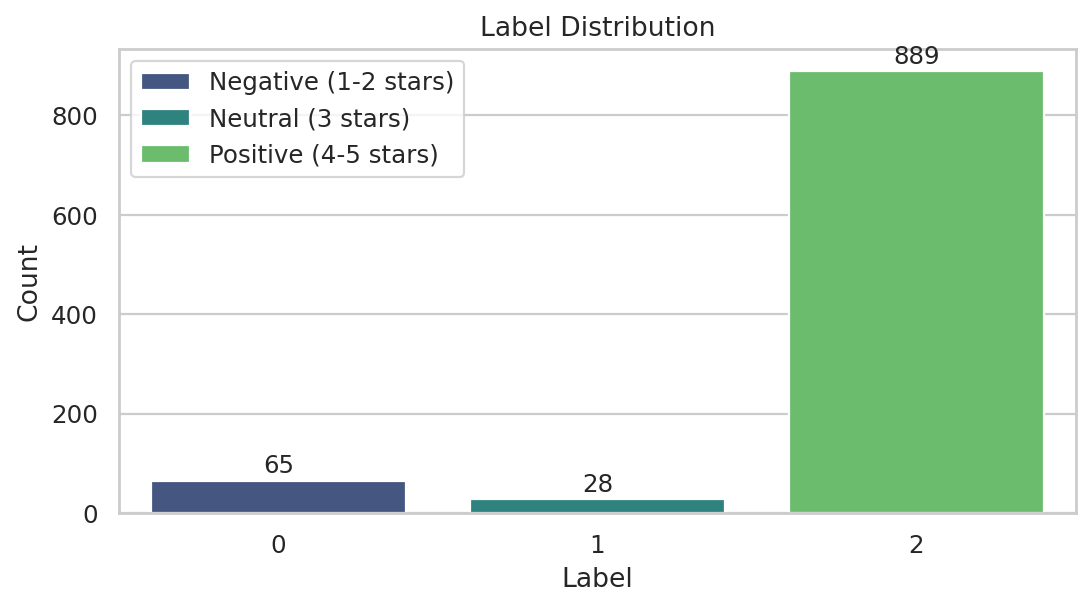

In [34]:
# A) label distribution
sentiment_names = {0: 'Negative (1-2 stars)', 1: 'Neutral (3 stars)', 2: 'Positive (4-5 stars)'}
label_dist_pd['label_name'] = label_dist_pd['label'].map(sentiment_names)

fig = plt.figure(figsize=(7, 4))
ax = sns.barplot(data=label_dist_pd, x="label", y="count", hue="label_name", palette="viridis", dodge=False)

for bar, count in zip(ax.patches, label_dist_pd["count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            str(count), ha='center', va='bottom', fontsize=11)

plt.title("Label Distribution")
plt.xlabel("Label")
plt.ylabel("Count")
plt.legend(loc="upper left")
plt.tight_layout()
display_figure(fig)


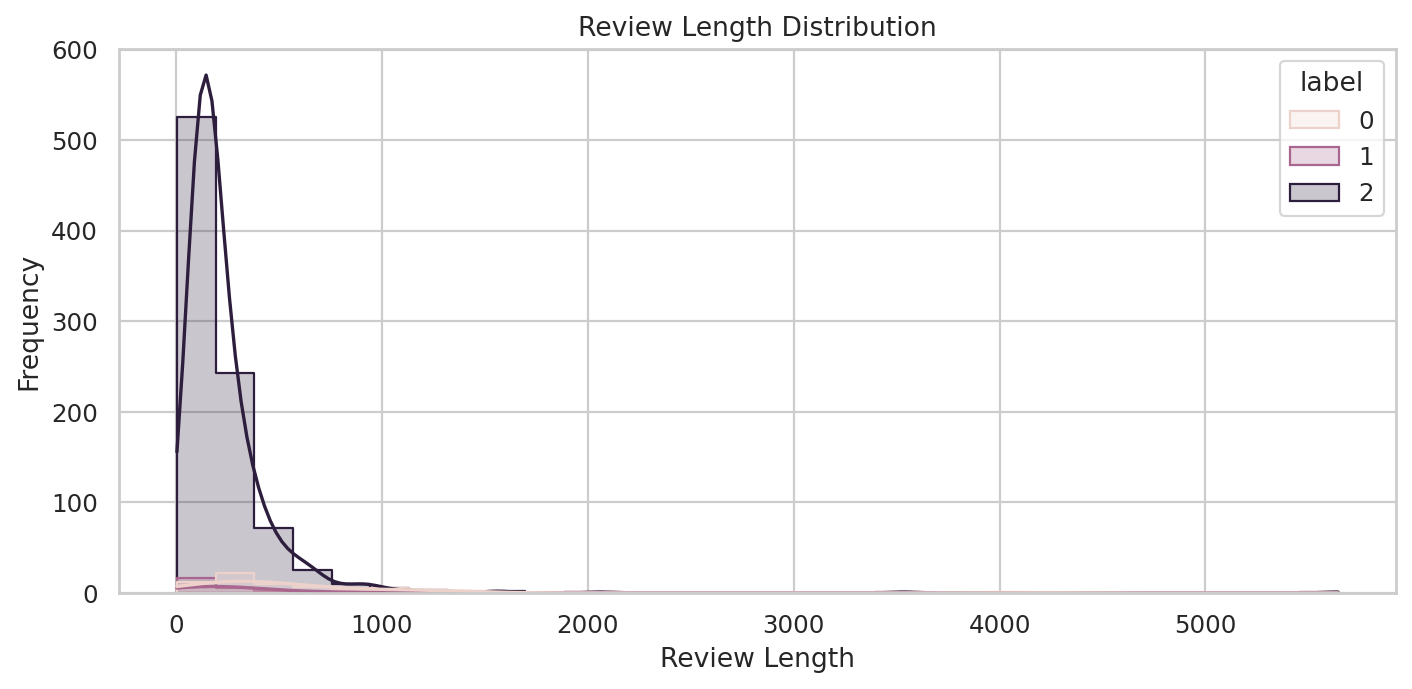

In [35]:
# B) review length distribution
fig = plt.figure(figsize=(9, 4.5))
sns.histplot(data=review_len_pd, x="review_len", hue="label", bins=30, kde=True, element="step")
plt.title("Review Length Distribution")
plt.xlabel("Review Length")
plt.ylabel("Frequency")
plt.tight_layout()
display_figure(fig)


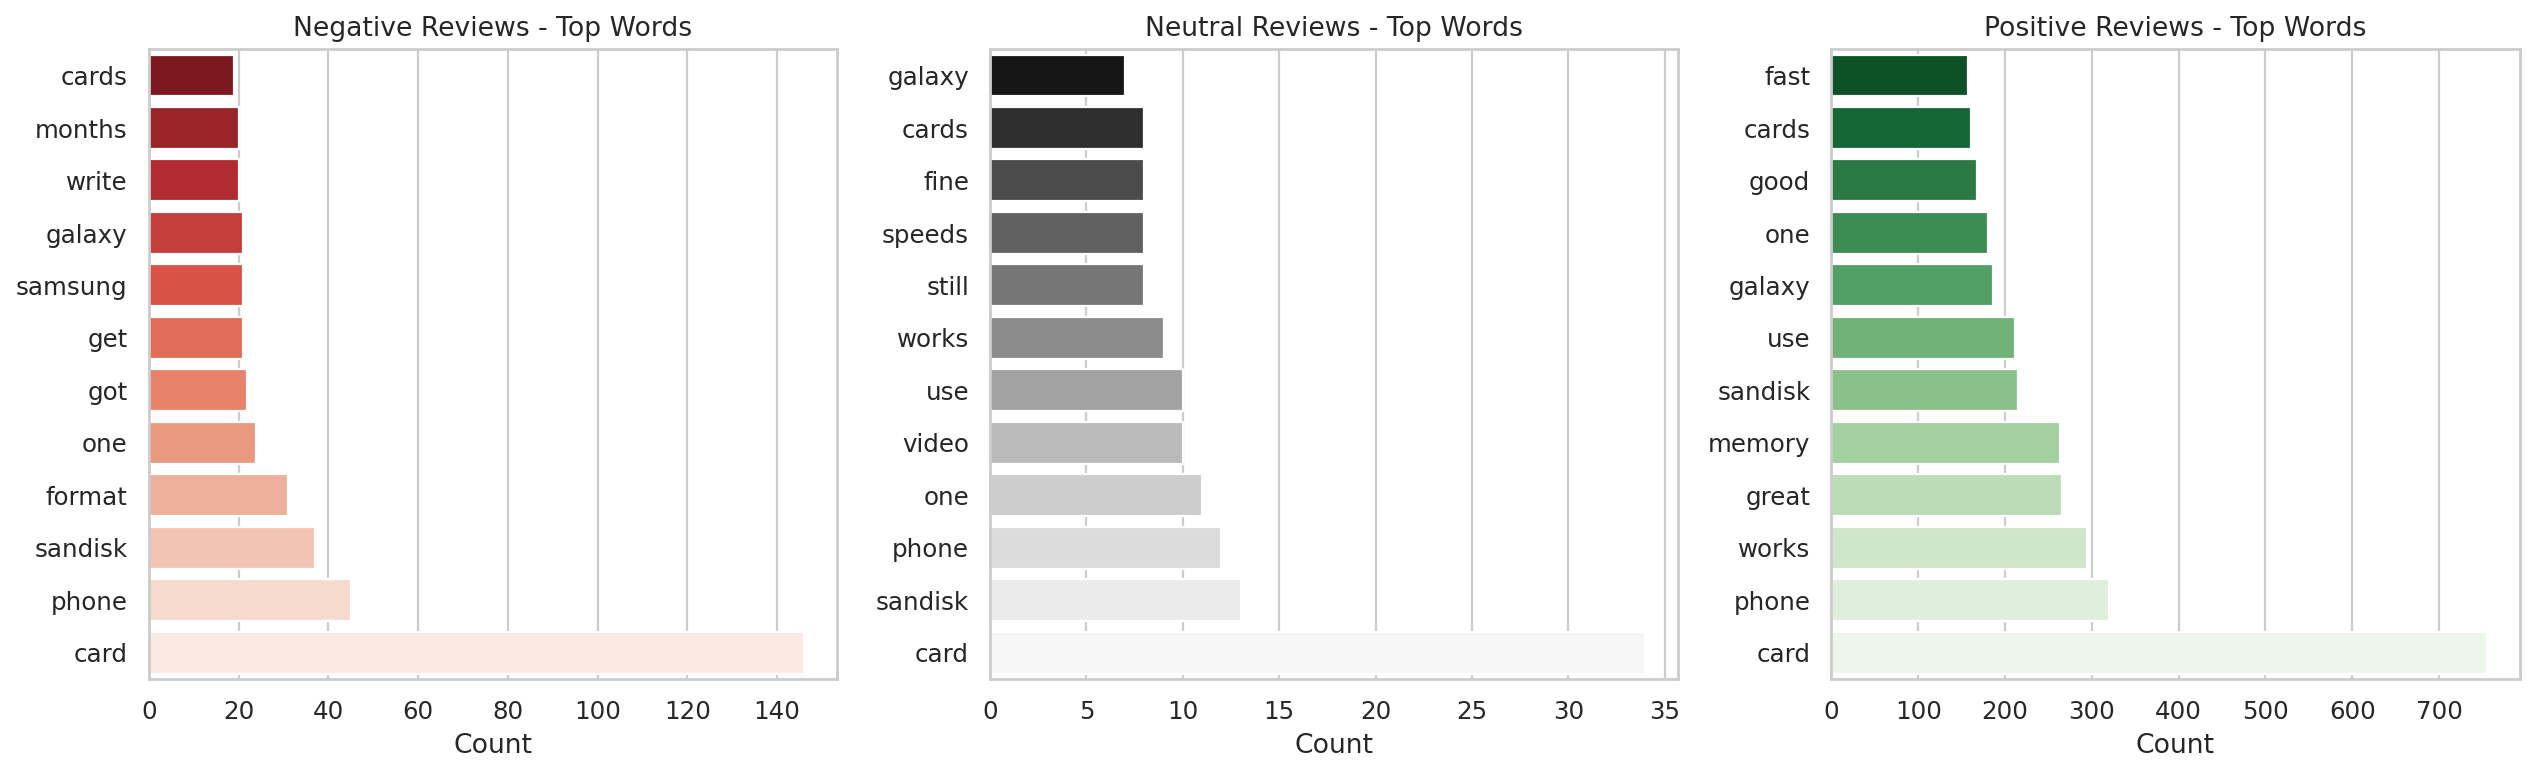

In [36]:
# B2) Top words by sentiment class (Spark aggregation result)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=120, sharex=False)
class_titles = {
    0: "Negative Reviews - Top Words",
    1: "Neutral Reviews - Top Words",
    2: "Positive Reviews - Top Words",
}
class_palettes = {0: "Reds_r", 1: "Greys_r", 2: "Greens_r"}

for ax, label_value in zip(axes, [0, 1, 2]):
    subset = top_words_pd[top_words_pd["label"] == label_value].sort_values("count", ascending=True)
    sns.barplot(data=subset, x="count", y="word", ax=ax, palette=class_palettes[label_value], hue="word", legend=False)
    ax.set_title(class_titles[label_value])
    ax.set_xlabel("Count")
    ax.set_ylabel("")

plt.tight_layout()
display_figure(fig)


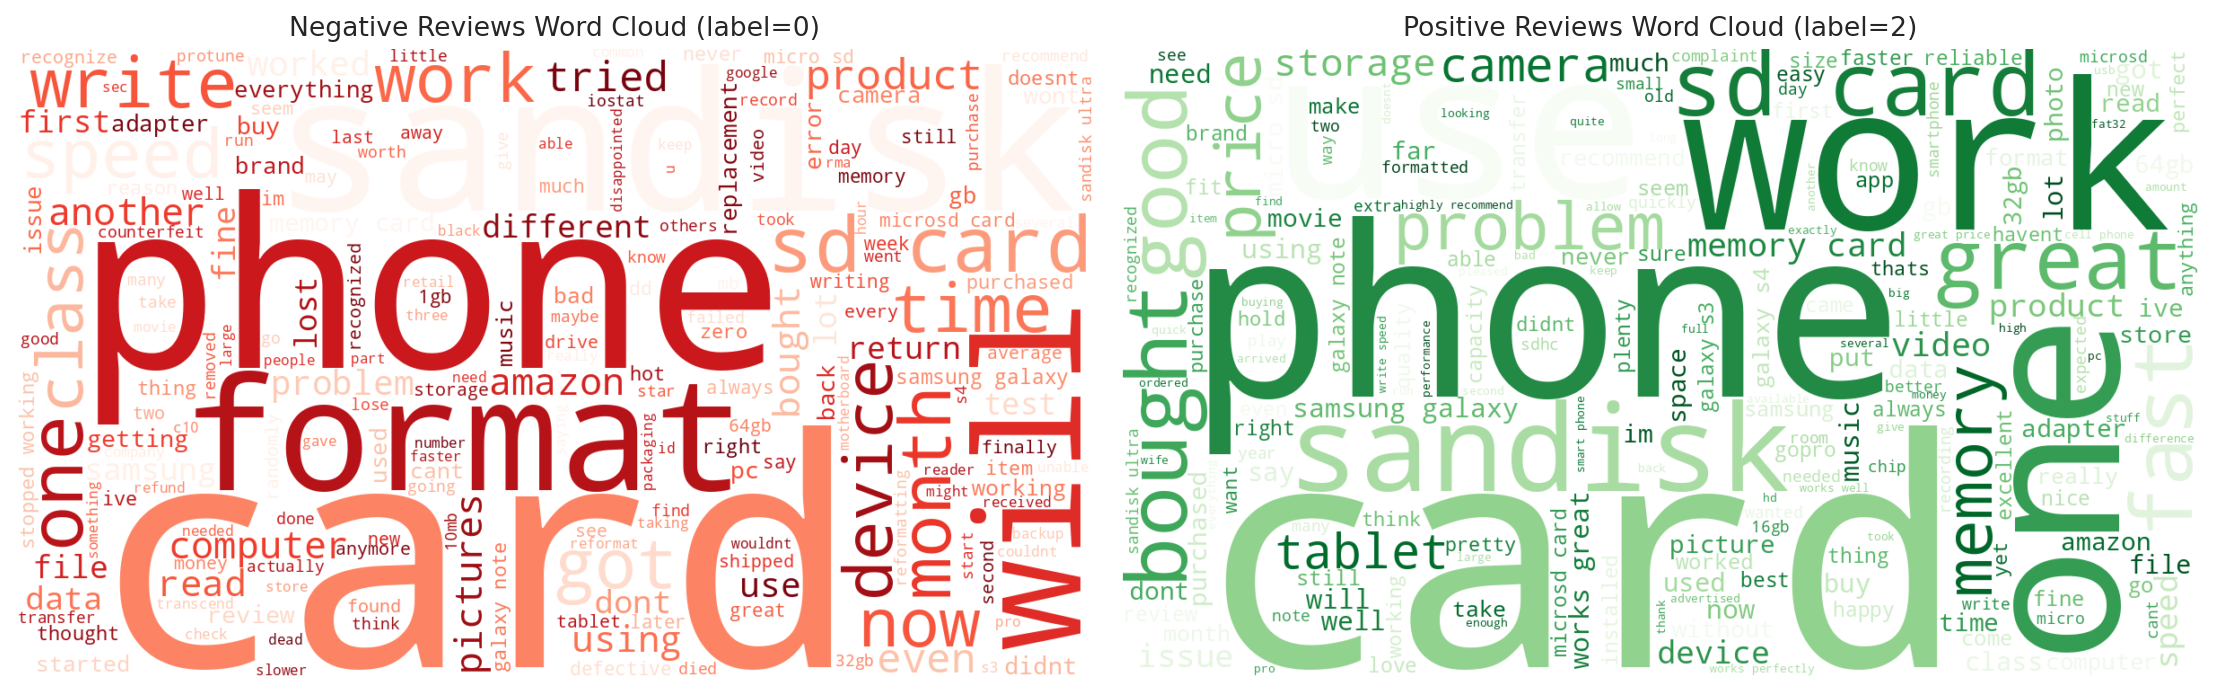

In [37]:
# B3) Word clouds for negative and positive reviews (placed after top-words bar chart)
from wordcloud import WordCloud

# Pull review text for label 0 and label 2 (same label mapping used in Task 1)
wc_pd = (
    df.select("reviewText", "label")
    .where(F.col("reviewText").isNotNull())
    .toPandas()
)

negative_text = " ".join(wc_pd.loc[wc_pd["label"] == 0, "reviewText"].astype(str).tolist())
positive_text = " ".join(wc_pd.loc[wc_pd["label"] == 2, "reviewText"].astype(str).tolist())

# Avoid empty-string failure in WordCloud
if not negative_text.strip():
    negative_text = "no negative words"
if not positive_text.strip():
    positive_text = "no positive words"

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

wc_negative = WordCloud(
    width=1200,
    height=700,
    background_color="white",
    colormap="Reds",
    max_words=200,
    random_state=2026,
).generate(negative_text)

wc_positive = WordCloud(
    width=1200,
    height=700,
    background_color="white",
    colormap="Greens",
    max_words=200,
    random_state=2026,
).generate(positive_text)

axes[0].imshow(wc_negative, interpolation="bilinear")
axes[0].axis("off")
axes[0].set_title("Negative Reviews Word Cloud (label=0)")

axes[1].imshow(wc_positive, interpolation="bilinear")
axes[1].axis("off")
axes[1].set_title("Positive Reviews Word Cloud (label=2)")

plt.tight_layout()
display_figure(fig)


In [38]:
# C) Statistical indicators table (mean/median/std/quartiles/min/max)
display(stats_pd.round(2))


,label,mean_len,median_len,std_len,min_len,q1_len,q3_len,max_len
0,0,541.03,367,562.63,19,236,630,4063
1,1,353.04,167,441.15,93,125,312,2054
2,2,236.74,160,285.70,4,116,263,5644


In [39]:
# C2) Correlation between numeric label and review length
print(f"Correlation(label, review_len) = {corr_val:.4f}")


Correlation(label, review_len) = -0.2368


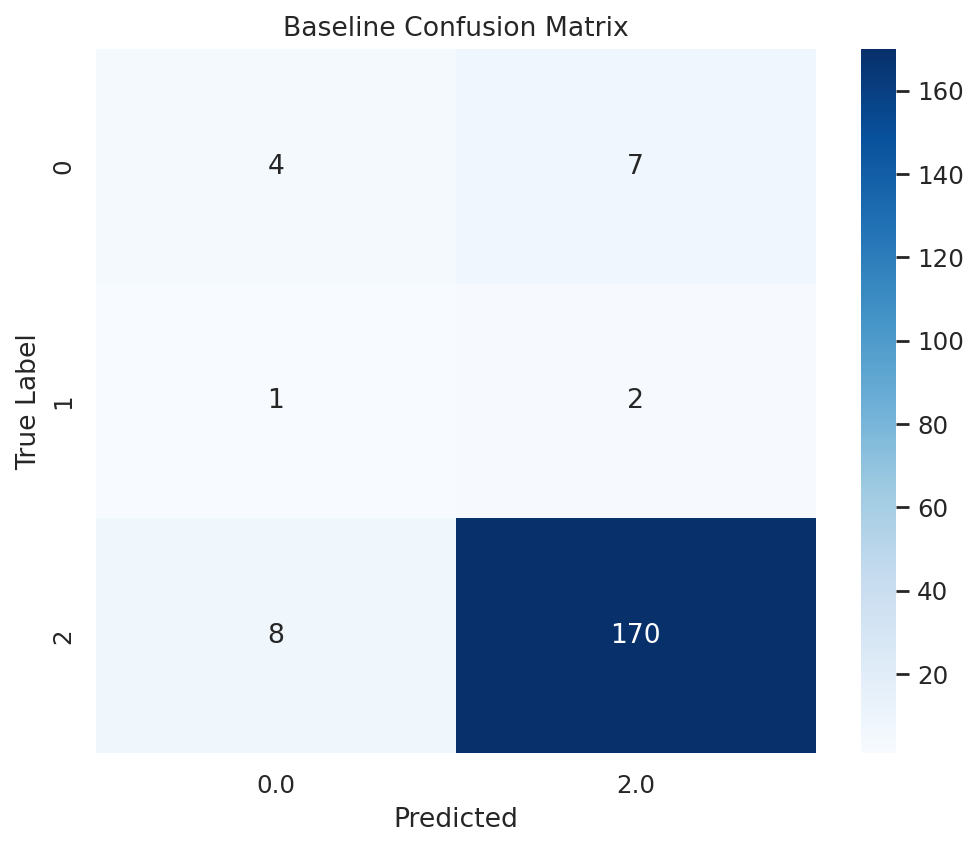

In [40]:
# D) baseline confusion matrix
fig = plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cm_table, annot=True, fmt=".0f", cmap="Blues")
plt.title("Baseline Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True Label")
plt.tight_layout()
display_figure(fig)


In [41]:
# E) Final summary table for submission
display(final_report_table)


,Section,Model,Embedding,Split,Seed,MainMetric,Accuracy,F1,F1_vs_Baseline
0,Task1 Baseline,TF-IDF + LogisticRegression,tfidf,Deterministic 80/20 (xxhash64),2026,f1,0.906200,0.90200,0.00000
1,Best Tuned,DecisionTree,tfidf,Deterministic 80/20 (xxhash64),2026,f1,0.942708,0.92385,0.02185
2,Improved LR,Weighted bigram LogisticRegression,tfidf_unigram_bigram,Deterministic 80/20 (xxhash64),2026,f1,0.911500,0.91000,0.00800


## Short Summary

This notebook develops a 3-class sentiment analysis system (negative/neutral/positive) primarily with PySpark and follows one consistent experimental protocol. We use a deterministic 80/20 split for all experiments and keep weighted F1 as the primary evaluation metric, while Accuracy is reported only as a secondary reference.

For Point 1 and Point 2, we build a baseline TF-IDF + Logistic Regression model, then compare multiple Spark ML classifiers (Decision Tree, Random Forest, Logistic Regression) with TF-IDF and Spark Word2Vec feature pipelines. Feature estimators are fitted inside Spark Pipelines on the training split only, avoiding test-set leakage. We also add a supplementary pretrained GloVe comparison using Spark NLP pretrained embeddings (`WordEmbeddingsModel.pretrained`) to cover an additional word embedding method while keeping the primary submitted implementation PySpark/Spark ML.

For Point 3, we apply Spark `CrossValidator` tuning with the same split and F1 evaluator. For Point 4, we present label distribution, review-length distribution, confusion matrix, descriptive statistics by label, correlation between label and review length, and top-word charts for each sentiment class, and negative/positive review word clouds.

For Point 5, we test class weighting, bi-gram TF-IDF features, and hyperparameter tuning. The final comparison table reports the baseline, the best tuned model, and the improved LR model with F1 difference against the baseline, so the conclusion is based on the actual measured results rather than assuming improvement.
